# Behavioral Pattern, notebook 5: what the modifier does to the final scores

`S = BP_modifier * sum(w_k * factor_k)` with the fusion weights fitted earlier (README of the dataset: Requirement Fulfillment 0.40, Effort 0.18, Task Complexity 0.16, Code
Ownership 0.16, Collaboration 0.07, Consistency 0.03). The base score uses the factor marks of the dataset table (the old Collaboration mark, since the new one is missing for most
sprints). Targets fixed in the protocol: Spearman between the score with and without the modifier at least 0.95 (the modifier must adjust, not reorder).

In [1]:
import sys, warnings, json, importlib.util
from pathlib import Path
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy.stats import spearmanr
from sklearn.metrics import cohen_kappa_score, confusion_matrix
sns.set_theme(style="whitegrid")
pd.set_option("display.width", 170); pd.set_option("display.max_columns", 30)
ROOT = Path("../../..").resolve()
spec = importlib.util.spec_from_file_location("bp_rules_nb", ROOT / "rules.py")
R = importlib.util.module_from_spec(spec); spec.loader.exec_module(R)
RESULTS = Path("results"); RESULTS.mkdir(exist_ok=True)
d = pd.read_csv(Path("../../dataset/bp_inputs.csv"))
PATTERNS = list(R.PATTERNS) + ["Balanced contributor"]
def run(thresholds, frame=None):
    frame = d if frame is None else frame
    out = []
    for r in frame.itertuples():
        co = None if pd.isna(r.Co) else float(r.Co)
        bim = None if pd.isna(r.bimodal) else int(r.bimodal)
        lc = None if pd.isna(r.late_churn) else float(r.late_churn)
        out.append(R.classify({"E": float(r.E), "C": float(r.C), "Co": co}, bim, thresholds, lc))
    return out

In [2]:
W = {"RF": 0.40, "E": 0.18, "TC": 0.16, "KO": 0.16, "Co_old": 0.07, "C": 0.03}
base = 100 * sum(w * d[k] for k, w in W.items())
rows, mods = [], {}
for name in ("proposal", "calibrated"):
    res = run(R.load_thresholds(name))
    m = np.array([r["score_modifier"] for r in res]); mods[name] = m
    s1 = base * m
    rows.append({"thresholds": name, "Spearman with vs without modifier": spearmanr(base, s1).correlation, "largest change (points)": float(np.abs(s1 - base).max()), "mean absolute change (points)": float(np.abs(s1 - base).mean()),
                 "share with modifier != 1": float((m != 1).mean())})
eff = pd.DataFrame(rows).round(3)
eff["meets target (>= 0.95)"] = eff["Spearman with vs without modifier"] >= 0.95
eff.to_csv(RESULTS / "modifier_effect.csv", index=False)
eff

,thresholds,Spearman with vs without modifier,largest change (points),mean absolute change (points),share with modifier != 1,meets target (>= 0.95)
0,proposal,0.995,7.616,0.428,0.119,True
1,calibrated,0.990,9.227,1.515,0.401,True


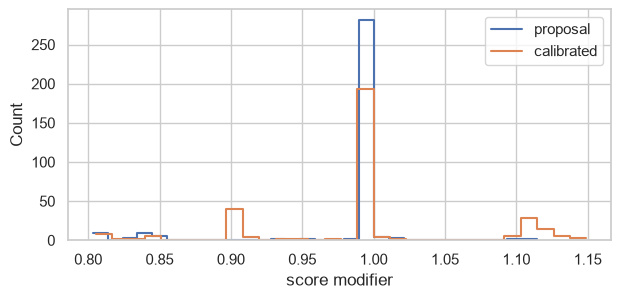

,count,mean,min,max
persona,,,,
Balanced contributor,191,1.000,1.000,1.000
Burst worker,4,0.977,0.950,0.995
Consistent deep contributor,57,1.115,1.100,1.149
Free rider,61,0.886,0.805,0.945
Reviewer or coordinator,6,1.007,1.001,1.013


In [3]:
fig, ax = plt.subplots(figsize=(7, 3))
for name, m in mods.items():
    sns.histplot(m, bins=30, label=name, ax=ax, element="step", fill=False)
ax.set_xlabel("score modifier"); ax.legend(); plt.show()
t = d.assign(mod=mods["calibrated"], persona=[r["persona"] for r in run(R.load_thresholds("calibrated"))])
t.groupby("persona").mod.agg(["count", "mean", "min", "max"]).round(3)

## Reading the results

**The modifier adjusts, it does not reorder.** The Spearman correlation between the final scores with and without the modifier is 0.990 for the final calibrated set (0.995 for the proposal's), above the 0.95 target. 40% of student-sprints get a modifier other than 1 (12% with the proposal's), largely the 61 Free riders (19%), who get 0.90 to 0.95 when Collaboration is not available and 0.80 to 0.85 when it is, and the 57 Consistent deep contributors (1.10 to 1.15). The largest single change is 9.2 points out of 100; the mean absolute change is 1.5 points.

The effort-only Free rider adjustment is the one an instructor should look at first: it applies to 41 real student-sprints, students with almost no observable activity whose team did not review, and it takes 5 to 10% off their base score.

The base score here uses the old propagated factor marks for the other factors, since the new Collaboration score is missing for most sprints; it shows the size of the effect, not the final marks of the deployed system.
